# Práctica 4 - Anatomía de un dataset de Machine Learning
**Sesión 4 - El dataset**

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino **interpretar correctamente los datos**.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("clientes_ecommerce.csv")

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [2]:
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


### Respuesta
1. ¿Qué representa una fila?
2. ¿Qué representa una columna?
3. ¿Cuál es la unidad de observación?
4. ¿Todas las columnas son características? Justifica.

**Respuesta:**  
1\. Un cliente  
2\. Una variable del cliente (edad, gasto, zona...)  
3\. El cliente  
4\. No. cliente_id es solo un identificador y compra_proximo_mes es lo que queremos predecir  

### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [3]:
df.shape

(400, 12)

### Respuesta
- Número de muestras:
- Número de columnas:
- ¿Tenemos el mismo número de características? ¿Por qué?

Numero de muestras: 400. Numero de columnas: 12. No, hay 10 caracteristicas porque quitamos el id y el target  

## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [4]:
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

### Ficha de variables
Clasifica cada variable como: **Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target**.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | int64 | Identificador | No |
| edad | int64 | Numerica discreta | Si |
| antiguedad_meses | float64 | Numerica discreta | Si |
| ingresos_anuales | float64 | Numerica continua | Si |
| gasto_mensual | float64 | Numerica continua | Si |
| num_compras | int64 | Numerica discreta | Si |
| devoluciones | int64 | Numerica discreta | Si |
| dispositivo | str (object) | Categorica nominal | Si |
| zona | str (object) | Categorica nominal | Si |
| nivel_fidelidad | str (object) | Categorica ordinal | Si |
| satisfaccion | int64 | Categorica ordinal | Si |
| compra_proximo_mes | str (object) | Target | No |

No clasifiques únicamente por `dtype`.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [5]:
print("dtype:", df["cliente_id"].dtype)
print("Valores únicos:", df["cliente_id"].nunique(), "de", len(df))
df["cliente_id"].head(10)

dtype: int64
Valores únicos: 400 de 400


0    20001
1    20002
2    20003
3    20004
4    20005
5    20006
6    20007
7    20008
8    20009
9    20010
Name: cliente_id, dtype: int64

### Respuesta
1. ¿Qué dtype tiene?
2. ¿Es por ello cuantitativa?
3. ¿Tiene sentido calcular su media?
4. ¿La incluirías inicialmente en \(X\)?
5. Justifica.


1\. int64  
2\. No, es un numero pero no mide nada  
3\. No, la media de un id no tiene sentido  
4\. No  
5\. Solo identifica al cliente y no aporta informacion para predecir  

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [6]:
df["satisfaccion"].value_counts().sort_index()

satisfaccion
1     33
2     58
3    123
4    116
5     70
Name: count, dtype: int64

Sabemos que 1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho.

### Respuesta
1. ¿Cómo la almacena pandas?
2. ¿Es simplemente numérica?
3. ¿Existe un orden?
4. ¿Nominal u ordinal?
5. Explica `dtype` frente a significado conceptual.


1\. Como un entero (int64)  
2\. No  
3\. Si, de 1 a 5  
4\. Ordinal  
5\. El dtype es como se guarda el dato y el tipo conceptual es lo que significa. Se guarda como numero pero es una categoria con orden  

## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Respuesta
1. ¿Cuántas muestras hay?
2. ¿Qué tipos técnicos aparecen?
3. ¿Todas las columnas tienen los mismos valores no nulos?
4. ¿Qué columnas contienen ausentes?
5. ¿Cuántos faltan?


1\. 400  
2\. int64, float64 y str  
3\. No  
4\. antiguedad_meses, ingresos_anuales y gasto_mensual  
5\. 5 en antiguedad_meses, 4 en ingresos_anuales y 3 en gasto_mensual, 12 en total  

### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [8]:
ausentes = df.isna().sum()
porcentaje = (df.isna().mean() * 100).round(2)
pd.DataFrame({"ausentes": ausentes, "porcentaje (%)": porcentaje})

,ausentes,porcentaje (%)
cliente_id,0,0.00
edad,0,0.00
antiguedad_meses,5,1.25
ingresos_anuales,4,1.00
gasto_mensual,3,0.75
num_compras,0,0.00
devoluciones,0,0.00
dispositivo,0,0.00
zona,0,0.00
nivel_fidelidad,0,0.00


### Reflexión
¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000? ¿Por qué son útiles los porcentajes?

No. 5 de 50 es un 10 % y 5 de 100.000 casi nada. El porcentaje sirve para ver lo importantes que son los ausentes segun el tamaño del dataset  

## Parte 4 - Construcción de X e y
Queremos predecir: **¿realizará el cliente una compra el próximo mes?**

### Ejercicio 8 - Variable objetivo

In [9]:
y = df["compra_proximo_mes"]

print(y.head())
print("Forma de y:", y.shape)

0    No
1    No
2    Sí
3    Sí
4    No
Name: compra_proximo_mes, dtype: str
Forma de y: (400,)


### Respuesta
1. ¿Qué representa cada elemento de \(y\)?
2. ¿Cuántos contiene?
3. ¿Por qué el target no debe incluirse también en \(X\)?


1\. Si el cliente compro o no el mes siguiente  
2\. 400  
3\. Porque es lo que queremos predecir, si lo metemos en X el modelo ya tendria la respuesta  

### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [10]:
features = ["edad", "antiguedad_meses", "ingresos_anuales", "gasto_mensual", "num_compras",
            "devoluciones", "dispositivo", "zona", "nivel_fidelidad", "satisfaccion"]
X = df[features]

display(X.head())
print("Forma de X:", X.shape)

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion
0,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5
1,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2
2,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5
3,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4
4,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4


Forma de X: (400, 10)


### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n =\) 400
- \(p =\) 10
- \(X.shape =\) (400, 10)
- \(y.shape =\) (400,)

n es el numero de clientes y p el numero de caracteristicas. X tiene una fila por cliente y una columna por caracteristica, e y tiene una etiqueta por cliente

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11
1. ¿Tenemos \(X\)?
2. ¿Tenemos \(y\)?
3. ¿Está etiquetado?
4. ¿Puede usarse para aprendizaje supervisado?
5. ¿Qué tipo de problema es predecir `compra_proximo_mes`?
6. ¿Binario o multiclase?
7. ¿Cuáles son las clases?

**Respuesta:**  
1\. Si  
2\. Si  
3\. Si  
4\. Si  
5\. Clasificacion  
6\. Binario  
7\. Si y No  

## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [11]:
for col in ["dispositivo", "zona", "nivel_fidelidad", "compra_proximo_mes"]:
    print(f"--- {col} ---")
    display(pd.DataFrame({
        "absoluta": df[col].value_counts(),
        "relativa": df[col].value_counts(normalize=True).round(4),
        "porcentaje (%)": (df[col].value_counts(normalize=True) * 100).round(2),
    }))

--- dispositivo ---


,absoluta,relativa,porcentaje (%)
dispositivo,,,
Móvil,242,0.6050,60.50
Ordenador,133,0.3325,33.25
Tablet,25,0.0625,6.25


--- zona ---


,absoluta,relativa,porcentaje (%)
zona,,,
Este,89,0.2225,22.25
Sur,80,0.2000,20.00
Norte,79,0.1975,19.75
Oeste,76,0.1900,19.00
Centro,76,0.1900,19.00


--- nivel_fidelidad ---


,absoluta,relativa,porcentaje (%)
nivel_fidelidad,,,
Bronce,162,0.4050,40.50
Plata,105,0.2625,26.25
Oro,83,0.2075,20.75
Platino,50,0.1250,12.50


--- compra_proximo_mes ---


,absoluta,relativa,porcentaje (%)
compra_proximo_mes,,,
No,246,0.615,61.5
Sí,154,0.385,38.5


### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | Movil | 242 | 60,50 % |
| zona | Este | 89 | 22,25 % |
| nivel_fidelidad | Bronce | 162 | 40,50 % |
| compra_proximo_mes | No | 246 | 61,50 % |

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

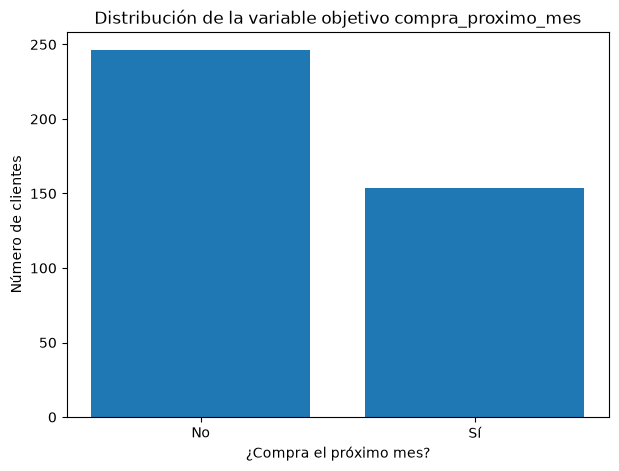

In [12]:
conteo_target = df["compra_proximo_mes"].value_counts()

plt.figure(figsize=(7,5))
plt.bar(conteo_target.index, conteo_target.values)
plt.title("Distribución de la variable objetivo compra_proximo_mes")
plt.xlabel("¿Compra el próximo mes?")
plt.ylabel("Número de clientes")
plt.show()

### Interpretación
¿Las clases aparecen aproximadamente con la misma frecuencia? Justifica con datos.

No. Hay 246 No (61,5 %) y 154 Si (38,5 %), hay mas clientes que no compran  

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [13]:
df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].describe().round(2)

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.00,396.00,397.00,400.00,400.00
mean,46.40,36440.92,69.09,8.22,1.23
std,18.01,14325.23,39.02,2.78,1.14
min,18.00,9000.00,5.77,2.00,0.00
25%,33.00,26034.09,39.72,6.00,0.00
50%,45.00,36817.27,61.17,8.00,1.00
75%,59.00,45969.03,90.15,10.00,2.00
max,195.00,82925.37,260.00,17.00,5.00


### Interpretación
Escribe una conclusión breve para cada variable:
- **edad:** media 46 y mediana 45, pero hay un maximo de 195 años que es un error
- **ingresos_anuales:** media y mediana parecidas, unos 36.500 €, entre 9.000 y 83.000 €
- **gasto_mensual:** media 69 € y mediana 61 €, hay algunos clientes que gastan mucho (maximo 260 €)
- **num_compras:** unas 8 compras de media, entre 2 y 17
- **devoluciones:** la mayoria tiene entre 0 y 2, maximo 5

### Ejercicio 15 - Detectar algo sospechoso
1. ¿Hay algún valor poco razonable?
2. ¿En qué variable?
3. ¿Por qué es sospechoso?
4. ¿Lo eliminarías inmediatamente?
5. ¿Qué comprobarías antes?

**Respuesta:**  
1\. Si  
2\. En edad  
3\. Hay un cliente con 195 años es imposible  
4\. No  
5\. Comprobaria el dato original y si no se puede arreglar lo pondria como NaN  

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

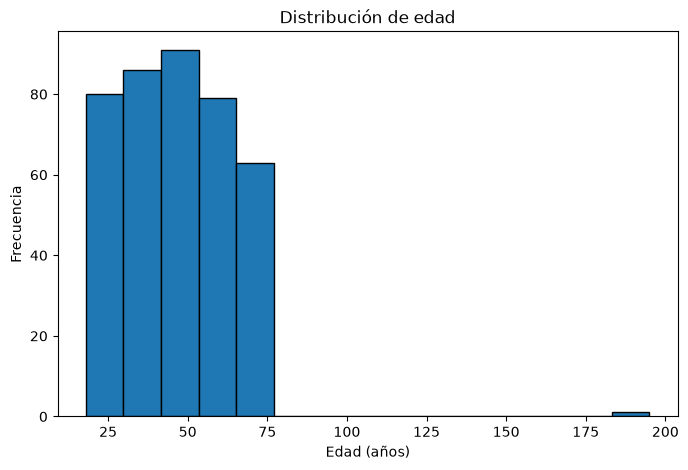

In [14]:
plt.figure(figsize=(8,5))
plt.hist(df["edad"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de edad")
plt.xlabel("Edad (años)")
plt.ylabel("Frecuencia")
plt.show()

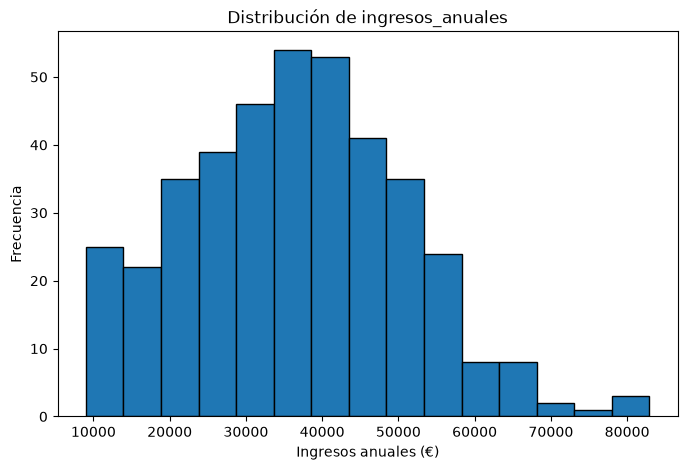

In [15]:
plt.figure(figsize=(8,5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de ingresos_anuales")
plt.xlabel("Ingresos anuales (€)")
plt.ylabel("Frecuencia")
plt.show()

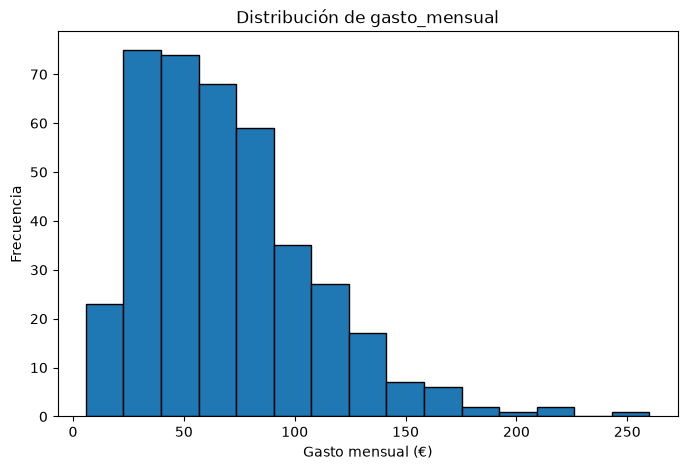

In [16]:
plt.figure(figsize=(8,5))
plt.hist(df["gasto_mensual"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de gasto_mensual")
plt.xlabel("Gasto mensual (€)")
plt.ylabel("Frecuencia")
plt.show()

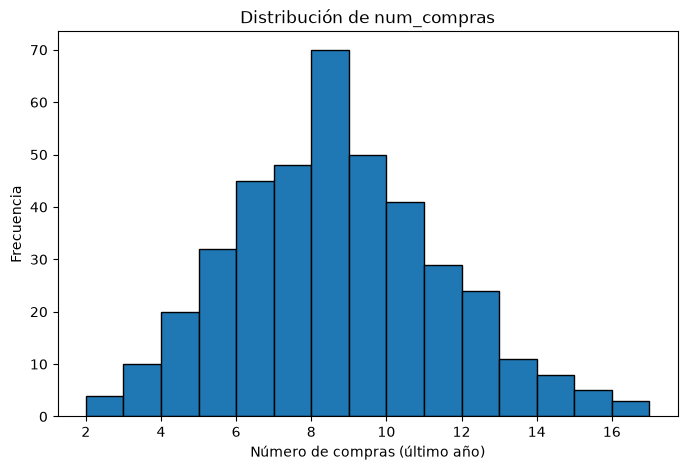

In [17]:
plt.figure(figsize=(8,5))
plt.hist(df["num_compras"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de num_compras")
plt.xlabel("Número de compras (último año)")
plt.ylabel("Frecuencia")
plt.show()

### Observaciones
- **edad:** repartida entre 18 y 75 años con el 195 muy separado
- **ingresos_anuales:** bastante simetrica con varios clientes justo en 9.000 €
- **gasto_mensual:** la mayoria entre 20 y 100 € con una cola hacia valores altos
- **num_compras:** forma de campana centrada en 8

## Parte 9 - Un mismo dataset, diferentes problemas
### Ejercicio 17 - Problema A
> ¿Realizará el cliente una compra el próximo mes?

Completa y justifica:
- Target: compra_proximo_mes  
- ¿Existe \(y\)?: si  
- Supervisado / no supervisado: supervisado tenemos la etiqueta  
- Clasificación / regresión / clustering: clasificacion el target es una categoria  
- Binaria / multiclase: binaria solo Si o No  

### Ejercicio 18 - Problema B
Supón una columna `gasto_proximo_mes` con cantidades monetarias.

> ¿Cuánto gastará el cliente el próximo mes?

1. ¿Cuál sería \(y\)?
2. ¿Qué tipo de variable?
3. ¿Supervisado?
4. ¿Clasificación o regresión?
5. ¿Por qué?

**Respuesta:**  
1\. gasto_proximo_mes  
2\. Numerica continua  
3\. Si  
4\. Regresion  
5\. Porque queremos predecir una cantidad no una categoria  

### Ejercicio 19 - Problema C
> Descubrir grupos de clientes similares sin grupos definidos previamente.

1. ¿Existe etiqueta de grupo?
2. ¿Necesitamos \(y\)?
3. ¿Supervisado o no supervisado?
4. ¿Qué técnica usaríamos?
5. ¿Qué variables podrían describir los grupos?

**Respuesta:**  
1\. No  
2\. No  
3\. No supervisado  
4\. Clustering por ejemplo K-Means  
5\. Edad, ingresos, gasto, numero de compras, devoluciones, satisfaccion o nivel de fidelidad  

## Parte 10 - Razonamiento
### Ejercicio 20 - ¿Una columna puede cambiar de papel?
¿Por qué una misma variable puede actuar como característica en un problema y como objetivo en otro?

**Respuesta:** Porque depende de lo que queramos predecir. Por ejemplo gasto_mensual es una caracteristica para predecir si compra, pero seria el target si quisieramos predecir cuanto gasta  

### Ejercicio 21 - ¿Qué está mal aquí?
Un compañero hace:

```python
X = df.drop(columns=["compra_proximo_mes"])
y = df["compra_proximo_mes"]
```

y afirma que todas las columnas de `X` ya son características adecuadas.

¿Estás de acuerdo? Identifica al menos dos cuestiones que revisarías.

**Respuesta:** No. Revisaria:  
1\. cliente_id sigue en X y no sirve para predecir  
2\. Hay columnas de texto que hay que codificar, valores ausentes y una edad de 195 años  

## Parte 11 - Ficha técnica
### Ejercicio 22

```text
FICHA DEL DATASET
=================
Nombre: Clientes e-commerce
Número de muestras: 400
Número de columnas: 12
Unidad de observación: cliente
Identificador: cliente_id
Target: compra_proximo_mes
Tipo de target: categorico binario (Si / No)
Número de features candidatas: 10
Features numéricas: edad, antiguedad_meses, ingresos_anuales, gasto_mensual, num_compras, devoluciones
Features categóricas nominales: dispositivo, zona
Features ordinales: nivel_fidelidad, satisfaccion
Datos etiquetados: Si
Valores ausentes: 12 (antiguedad_meses 5, ingresos_anuales 4, gasto_mensual 3)
Problema principal: predecir si el cliente comprara el proximo mes
Tipo de aprendizaje: supervisado
Tipo de tarea: clasificacion binaria
```

## Parte 12 - Conclusiones
### Ejercicio 23
Escribe entre **10 y 15 líneas** incluyendo: muestra, dimensiones, columnas vs. features, identificador, tipos de variables, target, \(X\), \(y\), etiquetado, ausentes, distribuciones, posible problema de calidad y tipo de problema de ML.

### Conclusiones
El dataset tiene 400 clientes y 12 columnas, cada fila es un cliente  
No todas las columnas son caracteristicas: cliente_id es un identificador y compra_proximo_mes es el target  
Quedan 10 caracteristicas, X tiene forma (400, 10) e y (400,)  
Hay variables numericas, categoricas nominales (dispositivo y zona) y ordinales (nivel_fidelidad y satisfaccion)  
satisfaccion se guarda como numero pero es ordinal  
El dataset esta etiquetado porque tenemos y para cada cliente  
Hay pocos ausentes, 12 en total en antiguedad, ingresos y gasto  
La mayoria usa el movil y es nivel Bronce  
El gasto mensual tiene algunos valores altos y los ingresos y las compras son mas simetricos  
Hay una edad de 195 años que es un error y habra que tratarla  
El target no esta equilibrado, 61,5 % No y 38,5 % Si  
Es un problema supervisado de clasificacion binaria  

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [ ]:
# TODO: ampliación opcional

# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

**Nombre recomendado:** `Practica_04_Apellido_Nombre.ipynb`